# LangGraph + Groq + LangSmith: Complete Multi-Agent Simulation

**Project:** Multi-Agent Research Assistant  
**Environment:** Google Colab  
**LLM provider:** Groq API  
**Model:** `openai/gpt-oss-120b` (use only if this model is available to your Groq account)

## What you will build

A supervisor agent receives a question and routes it to one specialist:
- **Research agent:** academic concepts, research and general explanations.
- **Technical agent:** programming, debugging and software engineering.

LangGraph executes the workflow. LangSmith records traces so you can inspect the graph and LLM calls.

### Architecture

```text
                 User question
                      |
                      v
                 Supervisor
                      |
              Conditional routing
                 /         \
                v           v
          Research agent  Technical agent
                \           /
                 v         v
                  Final answer
                      |
                     END
```

### Learning outcomes
1. Understand state, nodes, edges and conditional routing.
2. Connect LangGraph to Groq.
3. Enable LangSmith tracing.
4. Run and inspect a multi-agent simulation.
5. Test both routing paths.

**Important:** This is a learning prototype. The supervisor uses an LLM decision, so routing can occasionally be incorrect. It does not yet include external search tools, MCP, PostgreSQL persistence, authentication, or production safeguards.

## 0. Before you start

1. Open [Google Colab](https://colab.research.google.com/).
2. Create a new notebook.
3. Optionally rename it `LangGraph_Groq_LangSmith_Multi_Agent_Lab`.
4. In Colab's left sidebar, open **Secrets** (key icon).
5. Add these two secrets:
   - `GROQ_API_KEY`
   - `LANGSMITH_API_KEY`
6. Enable notebook access for both secrets.

Get keys from:
- [Groq Console](https://console.groq.com/keys)
- [LangSmith](https://smith.langchain.com/)

Never paste API keys into a notebook cell or share a notebook containing exposed keys.

## 1. Install the required packages

We use `%pip` so the packages are installed into the active notebook environment.

- `langgraph`: graph-based agent orchestration.
- `langchain-core`: message and model interfaces.
- `langchain-groq`: Groq chat model integration.
- `langsmith`: tracing and observability.

In [23]:
%pip install -q -U langgraph langchain-core langchain-groq langsmith

## 2. Configure API keys and LangSmith tracing

This cell reads secrets from Colab's Secrets panel. It does not print the keys.

`LANGSMITH_TRACING=true` enables tracing. `LANGSMITH_PROJECT` sets the project name that you will look for in LangSmith.

In [24]:
import os
from google.colab import userdata

# Read API keys from Colab Secrets (do not hard-code keys in this notebook).
groq_api_key = userdata.get("GROQ_API_KEY")
langsmith_api_key = userdata.get("LANGSMITH_API_KEY")

# Fail early with a helpful message if a secret is missing.
if not groq_api_key:
    raise ValueError("Missing GROQ_API_KEY. Add it in Colab Secrets and enable notebook access.")

if not langsmith_api_key:
    raise ValueError("Missing LANGSMITH_API_KEY. Add it in Colab Secrets and enable notebook access.")

os.environ["GROQ_API_KEY"] = groq_api_key
os.environ["LANGSMITH_API_KEY"] = langsmith_api_key

# Enable LangSmith tracing for LangChain/LangGraph runs.
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "multi-agent-research-lab"

print("API configuration completed. Keys were not displayed.")

API configuration completed. Keys were not displayed.


## 3. Create the shared graph state

A LangGraph state is the shared data structure passed between nodes.

In this project:
- `question`: the original user question.
- `route`: the specialist selected by the supervisor.
- `routing_reason`: the supervisor's explanation.
- `specialist_answer`: the specialist's response.
- `final_answer`: the answer returned to the user.

**Roman Urdu note:** State ko shared register samjhein. Har node is register se zaroori information read karta hai aur apna result update karta hai.

In [25]:
from typing import TypedDict

class AgentState(TypedDict):
    question: str
    route: str
    routing_reason: str
    specialist_answer: str
    final_answer: str

print("AgentState schema is ready.")

AgentState schema is ready.


## 4. Initialize the Groq language model

`ChatGroq` connects LangChain to the Groq API. The model runs on Groq's infrastructure; Colab does not download the model weights.

We use `temperature=0` to make outputs more consistent. It does not guarantee identical outputs or perfect routing.

**Model availability:** If Groq reports that the model ID is unavailable, check the models currently available to your account in Groq's documentation/console and replace the `model` value below.

In [26]:
from langchain_groq import ChatGroq

MODEL_NAME = "openai/gpt-oss-120b"

llm = ChatGroq(
    model=MODEL_NAME,
    temperature=0,
    max_retries=2,
)

print(f"Groq chat model configured: {MODEL_NAME}")

Groq chat model configured: openai/gpt-oss-120b


## 5. Build the supervisor agent

The supervisor does not write the specialist answer. Its job is to decide which worker should handle the question.

It returns two state updates:
- `route`: either `research` or `technical`.
- `routing_reason`: a short reason for its decision.

The parsing code is deliberately defensive: if the model's response does not contain a recognizable route, it falls back to `research`. For a production system, structured output or a validated schema would be preferable.

In [27]:
def supervisor_agent(state: AgentState) -> dict:
    """Choose the best specialist for the user's question."""

    question = state["question"]

    prompt = f"""
You are the supervisor of a two-agent assistant.

Choose exactly one specialist:
- research: academic topics, research methods, concepts,
  literature-style explanations, and general knowledge.
- technical: programming, coding, debugging, software engineering,
  and technical implementation.

Return these two lines:
ROUTE: research
REASON: short explanation

or

ROUTE: technical
REASON: short explanation

User question: {question}
"""

    response = llm.invoke(prompt)
    output = str(response.content).strip()
    output_lower = output.lower()

    # Parse the route from the model response.
    if "route: technical" in output_lower:
        route = "technical"
    elif "route: research" in output_lower:
        route = "research"
    else:
        # Safe learning-demo fallback if the format is unexpected.
        route = "research"

    # Parse the reason, if present.
    reason = "Selected based on the question type."
    for line in output.splitlines():
        if line.strip().lower().startswith("reason:"):
            reason = line.split(":", 1)[1].strip()
            break

    return {
        "route": route,
        "routing_reason": reason,
    }

## 6. Build the research specialist

This node receives the same shared state. It reads `question`, calls the model with a role-specific system instruction, and returns its answer.

**Roman Urdu note:** Research agent ko uski specific responsibility di gayi hai. System message model ko batata hai ke jawab kis role ke mutabiq dena hai.

In [28]:
from langchain_core.messages import SystemMessage, HumanMessage

def research_agent(state: AgentState) -> dict:
    """Answer academic, research and conceptual questions."""

    messages = [
        SystemMessage(content=(
            "You are an academic research assistant. "
            "Explain concepts clearly, organize the answer with headings "
            "when useful, distinguish facts from uncertainty, and avoid "
            "inventing citations or sources."
        )),
        HumanMessage(content=state["question"]),
    ]

    response = llm.invoke(messages)
    answer = str(response.content)

    return {
        "specialist_answer": answer,
        "final_answer": answer,
    }

## 7. Build the technical specialist

This node handles programming and software-engineering questions. It also writes its result into the shared state.

In [29]:
def technical_agent(state: AgentState) -> dict:
    """Answer programming and software-engineering questions."""

    messages = [
        SystemMessage(content=(
            "You are a careful technical assistant. "
            "Help with programming, debugging and software engineering. "
            "Explain assumptions and give step-by-step examples when useful. "
            "Do not claim that code was executed unless it actually was."
        )),
        HumanMessage(content=state["question"]),
    ]

    response = llm.invoke(messages)
    answer = str(response.content)

    return {
        "specialist_answer": answer,
        "final_answer": answer,
    }

## 8. Assemble the LangGraph workflow

Key concepts:
- `StateGraph(AgentState)`: creates a graph that uses our state schema.
- `add_node`: registers a Python function as a graph node.
- `add_edge`: creates a fixed connection.
- `add_conditional_edges`: chooses the next node based on a routing function.
- `START` and `END`: special graph entry and exit points.
- `compile`: validates and prepares the graph for execution.

The supervisor is always called first. Only one specialist is called for each run.

In [30]:
from langgraph.graph import StateGraph, START, END

# Create a graph whose nodes share AgentState.
builder = StateGraph(AgentState)

# Register each agent function as a named node.
builder.add_node("supervisor", supervisor_agent)
builder.add_node("research_agent", research_agent)
builder.add_node("technical_agent", technical_agent)

def select_agent(state: AgentState) -> str:
    """Return the next node name based on the supervisor's route."""
    if state["route"] == "technical":
        return "technical_agent"
    return "research_agent"

# Every run begins with the supervisor.
builder.add_edge(START, "supervisor")

# Route from the supervisor to exactly one specialist.
builder.add_conditional_edges(
    "supervisor",
    select_agent,
    {
        "research_agent": "research_agent",
        "technical_agent": "technical_agent",
    },
)

# Either specialist completes the graph.
builder.add_edge("research_agent", END)
builder.add_edge("technical_agent", END)

# Compile the graph before invoking it.
graph = builder.compile()

print("LangGraph workflow compiled successfully.")

LangGraph workflow compiled successfully.


## 9. Visualize the graph (optional)

The following cell attempts to display a Mermaid diagram. If the notebook environment cannot render it, the text architecture in the introduction still describes the workflow.

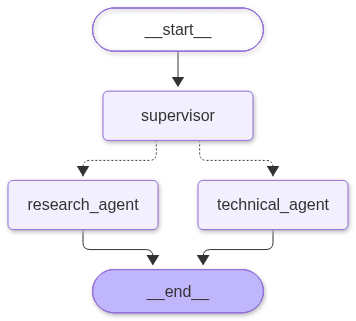

In [18]:
try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as error:
    print("Graph image could not be rendered in this runtime.")
    print("You can still run the graph; visualization error:", error)

## 10. Run one simulation

Change the `question` value to try different inputs.

The `config` object adds a run name, tags and metadata. LangSmith uses the environment configuration from Section 2 to record the run.

In [31]:
question = "Explain how a ai works."

initial_state: AgentState = {
    "question": question,
    "route": "",
    "routing_reason": "",
    "specialist_answer": "",
    "final_answer": "",
}

result = graph.invoke(
    initial_state,
    config={
        "run_name": "multi-agent-research-demo",
        "tags": ["colab", "langgraph", "multi-agent"],
        "metadata": {
            "project": "multi-agent-research-lab",
            "model": MODEL_NAME,
        },
    },
)

print("USER QUESTION:")
print(result["question"])

print("\nSELECTED AGENT:")
print(result["route"])

print("\nSUPERVISOR REASON:")
print(result["routing_reason"])

print("\nFINAL ANSWER:")
print(result["final_answer"])

USER QUESTION:
Explain how a ai works.

SELECTED AGENT:
research

SUPERVISOR REASON:
The question asks for a conceptual explanation of how AI functions, which aligns with academic and general‑knowledge topics rather than specific programming or debugging.

FINAL ANSWER:
**How Artificial Intelligence (AI) Works – A Structured Overview**

---

## 1. What “AI” Means

| Term | Typical Meaning |
|------|-----------------|
| **Artificial Intelligence** | The broad field concerned with building systems that can perform tasks that normally require human intelligence (e.g., perception, reasoning, decision‑making, language). |
| **Machine Learning (ML)** | A sub‑field of AI that focuses on algorithms that improve their performance automatically through experience (data). |
| **Deep Learning (DL)** | A subset of ML that uses multi‑layered artificial neural networks to learn hierarchical representations of data. |

*Fact:* Modern AI applications (image recognition, language models, recommendation 

## 11. Test the technical route

This example should normally be routed to the technical specialist. The supervisor is an LLM, so treat the route as a model decision rather than a guaranteed rule.

In [34]:
technical_question = "Write a Python function to reverse a singly linked list."

technical_state: AgentState = {
    "question": technical_question,
    "route": "",
    "routing_reason": "",
    "specialist_answer": "",
    "final_answer": "",
}

technical_result = graph.invoke(
    technical_state,
    config={
        "run_name": "technical-agent-demo",
        "tags": ["colab", "technical-test"],
    },
)

print("Selected agent:", technical_result["route"])
print("Reason:", technical_result["routing_reason"])
print("\nAnswer:")
print(technical_result["final_answer"])

Selected agent: technical
Reason: The request involves implementing a Python function to manipulate a data structure, which falls under programming and coding.

Answer:
Below is a self‑contained example that shows:

1. **A minimal singly‑linked‑list node definition** (`ListNode`).
2. **An iterative algorithm** (`reverse_list`) that runs in O(n) time and O(1) extra space.
3. **A recursive version** (`reverse_list_recursive`) for completeness.
4. **A tiny test harness** that builds a list, reverses it, and prints the result so you can copy‑paste and run it yourself.

```python
# ------------------------------------------------------------
# 1.  Node definition
# ------------------------------------------------------------
class ListNode:
    """A node of a singly linked list."""
    __slots__ = ("val", "next")          # saves a little memory, optional

    def __init__(self, val: int, next: 'ListNode' = None):
        self.val = val
        self.next = next

    def __repr__(self):
    

## 12. Run a small batch of test questions

Each question invokes the supervisor and one specialist, so each test consumes Groq API usage. Keep the list short while learning.

These are integration tests against a live model, not deterministic unit tests. A routing mismatch does not necessarily mean the graph wiring is broken.

In [35]:
test_questions = [
    "Explain the importance of research methodology.",
    "Write a Python function to check whether a number is prime.",
]

for index, question in enumerate(test_questions, start=1):
    state: AgentState = {
        "question": question,
        "route": "",
        "routing_reason": "",
        "specialist_answer": "",
        "final_answer": "",
    }

    output = graph.invoke(
        state,
        config={
            "run_name": f"batch-test-{index}",
            "tags": ["batch-test"],
        },
    )

    print("=" * 70)
    print(f"TEST {index}")
    print("Question:", question)
    print("Selected agent:", output["route"])
    print("Routing reason:", output["routing_reason"])
    print("Answer preview:", output["final_answer"][:600])
    print()

TEST 1
Question: Explain the importance of research methodology.
Selected agent: research
Routing reason: The question asks about the significance of research methodology, which pertains to academic concepts and the study of research methods.
Answer preview: **The Importance of Research Methodology**

---

## 1. What Is Research Methodology?

Research methodology is the systematic plan that guides how a study is designed, conducted, and reported. It includes:

| Component | What It Covers |
|-----------|----------------|
| **Philosophical stance** (e.g., positivist, interpretivist) | Underlying assumptions about reality and knowledge |
| **Research design** (e.g., experimental, case‑study, survey) | Overall structure for data collection and analysis |
| **Data‑collection techniques** (e.g., interviews, questionnaires, sensors) | Specific tools and

TEST 2
Question: Write a Python function to check whether a number is prime.
Selected agent: technical
Routing reason: The request involves

## 13. Inspect the execution in LangSmith

1. Open [LangSmith](https://smith.langchain.com/).
2. Select the project named **`multi-agent-research-lab`**.
3. Find the latest run, such as `multi-agent-research-demo`.
4. Open it and inspect the graph execution and model calls.

A typical trace contains the graph run, the supervisor node and its LLM call, followed by one specialist node and its LLM call. The exact presentation may vary by LangSmith version.

### Remember the three roles

| Component | Responsibility |
|---|---|
| LangGraph | Executes and routes the workflow |
| Groq | Hosts and serves the language model |
| LangSmith | Records and helps inspect execution traces |

**Roman Urdu:** LangGraph workflow chalata hai, Groq model ka response deta hai, aur LangSmith execution ko observe/trace karne mein help karta hai.

## 14. Troubleshooting

| Error | What to check |
|---|---|
| `401 Unauthorized` | Verify the Groq API key and that the secret is enabled in Colab. |
| `404` or model not found | Verify that `openai/gpt-oss-120b` is available to your Groq account; update `MODEL_NAME` if needed. |
| `429 Too Many Requests` | You may have reached a rate limit or usage limit. Wait and retry. |
| `SecretNotFoundError` | Check exact secret names: `GROQ_API_KEY` and `LANGSMITH_API_KEY`. |
| No LangSmith traces | Check `LANGSMITH_TRACING`, the LangSmith key, project name and network access. |
| Package/import error | Rerun the installation cell; if needed, restart the Colab runtime and run cells from the top. |

Colab runtimes are temporary. Save the notebook in Google Drive. After a runtime reset, rerun the installation, secrets, model, agent and graph cells in order.

## 15. Mini assessment

Try answering these without looking back:

1. What is the purpose of `AgentState`?
2. What is the difference between a node and an edge?
3. Why do we use `add_conditional_edges`?
4. Which component executes the graph?
5. Which component records traces?
6. Why does the supervisor run before the specialist?

### Suggested next upgrades

Once this notebook runs successfully, extend it in stages:
1. Add a Gradio chat interface.
2. Add tools and MCP integration.
3. Add PostgreSQL-backed persistence/checkpointing.
4. Add human approval for sensitive actions.
5. Add LangSmith evaluations and compare routing quality.

Do not add all upgrades at once. First make sure both specialist paths run and their traces appear in LangSmith.